In [1]:
# Import Libraries and Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

# Load the processed dataset from Notebook 2
df_model = pd.read_csv('processed_satisfaction_data.csv')
print("Processed Dataset Loaded Successfully! Shape:", df_model.shape)

Processed Dataset Loaded Successfully! Shape: (129880, 23)


In [2]:
# Handle Class Encoding and Separate Features & Target
if 'Class' in df_model.columns and df_model['Class'].dtype == 'object':
    class_mapping = {'Business': 2, 'Eco Plus': 1, 'Eco': 0}
    df_model['Class'] = df_model['Class'].map(class_mapping)
    print("'Class' column successfully encoded to numeric values.")

# Define Features (X) & Target (y)
X = df_model.drop(columns=['satisfaction_encoded'])
y = df_model['satisfaction_encoded']

# Ensure all columns in X are numeric
X = X.select_dtypes(include=[np.number])
print("Features and Target prepared successfully!")

'Class' column successfully encoded to numeric values.
Features and Target prepared successfully!


In [3]:
# Train-Test Split and Feature Scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training Set Shape (X_train): {X_train.shape}")
print(f"Testing Set Shape (X_test): {X_test.shape}")

# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature Scaling (Standardization) Completed!")

Training Set Shape (X_train): (103904, 22)
Testing Set Shape (X_test): (25976, 22)
Feature Scaling (Standardization) Completed!


In [4]:
# Initialize and Train the Three Models
print("--- Starting Model Training ---")

# 1. Logistic Regression
print("Training Logistic Regression...")
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression Training Completed.")

# 2. Random Forest
print("\nTraining Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest Training Completed.")

# 3. XGBoost Classifier
print("\nTraining XGBoost Classifier...")
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_model.fit(X_train, y_train)
print("XGBoost Training Completed.")

print("\nAll models have been successfully trained and fitted!")

--- Starting Model Training ---
Training Logistic Regression...
Logistic Regression Training Completed.

Training Random Forest Classifier...
Random Forest Training Completed.

Training XGBoost Classifier...
XGBoost Training Completed.

All models have been successfully trained and fitted!


In [5]:
# Evaluate Models

# 1. Generate Predictions on Test Set
# Logistic Regression uses scaled test data
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# Random Forest & XGBoost use unscaled test data
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# 2. Function to compute metrics
def evaluate_model(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc = roc_auc_score(y_true, y_prob)
    return {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'ROC-AUC': roc}

# 3. Calculate metrics for all three models
evaluation_results = {
    'Logistic Regression': evaluate_model(y_test, lr_pred, lr_prob),
    'Random Forest': evaluate_model(y_test, rf_pred, rf_prob),
    'XGBoost': evaluate_model(y_test, xgb_pred, xgb_prob)
}

# 4. Convert results to a clean DataFrame for comparison
metrics_df = pd.DataFrame(evaluation_results).T
print("--- Model Performance Evaluation Summary ---")
display(metrics_df)

--- Model Performance Evaluation Summary ---


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.829227,0.844960,0.842583,0.843770,0.903122
Random Forest,0.954573,0.967376,0.949005,0.958103,0.992451
XGBoost,0.956845,0.970267,0.950271,0.960165,0.993635


--- Top 10 Most Important Features for Passenger Satisfaction ---


,Feature,Importance
8,Inflight entertainment,0.397836
3,Seat comfort,0.117308
20,Customer Type encoded,0.079758
10,Ease of Online booking,0.063810
1,Class,0.036186
21,Type of Travel encoded,0.032664
4,Departure/Arrival time convenient,0.029247
14,Checkin service,0.028026
6,Gate location,0.026081
9,Online support,0.025854


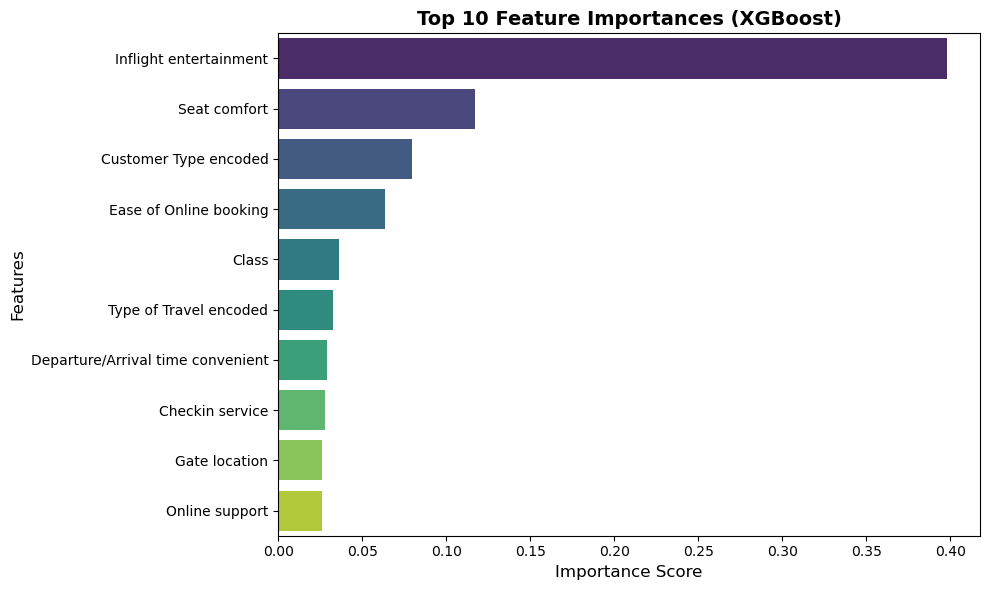

In [6]:
# Extract and Plot Feature Importances from XGBoost Model
# XGBoost provides feature_importances_ which shows how much each feature contributed

feature_importances = xgb_model.feature_importances_
feature_names = X.columns

# Create a DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Display top 10 most important features
print("--- Top 10 Most Important Features for Passenger Satisfaction ---")
display(importance_df.head(10))

# Plotting the Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')
plt.title('Top 10 Feature Importances (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

In [7]:
# Save the Best Trained Model (XGBoost) using joblib
import joblib

# Saving the trained XGBoost model to disk
joblib.dump(xgb_model, 'best_airline_satisfaction_model.pkl')
print("Best Model (XGBoost) Saved Successfully as 'best_airline_satisfaction_model.pkl'!")

# Also saving the scaler for future preprocessing consistency
joblib.dump(scaler, 'scaler.pkl')
print("StandardScaler Saved Successfully as 'scaler.pkl'!")

Best Model (XGBoost) Saved Successfully as 'best_airline_satisfaction_model.pkl'!
StandardScaler Saved Successfully as 'scaler.pkl'!
